# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [4]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


# Static PNG output so the charts render on GitHub (needs: pip install -U kaleido)
# For interactive charts while working locally, comment this line out
import plotly.io as pio
pio.renderers.default = 'png'

## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


World average life expectancy 2007: 67.0 years
continent
Africa     -12.2
Asia         3.7
Americas     6.6
Europe      10.6
Oceania     13.7
Name: dev_from_avg, dtype: float64


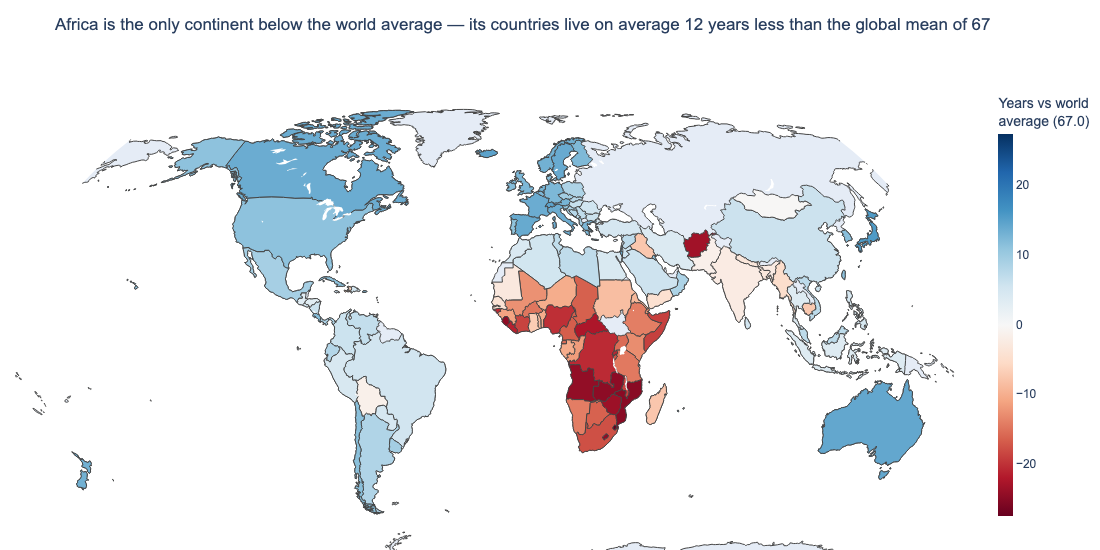

In [5]:
# Task 1
# Chart type: px.choropleth — built-in world geometry via ISO-3 codes; a global pattern needs no basemap.
# Colour scale: diverging (RdBu) centred at 0 — the data is above/below the world average.

# ── Data prep ─────────────────────────────────────────────────────────────────
gm = px.data.gapminder()
gm_2007 = gm.loc[gm['year'] == 2007].copy()

world_avg = gm_2007['lifeExp'].mean()                       # unweighted mean across countries
gm_2007['dev_from_avg'] = gm_2007['lifeExp'] - world_avg    # positive = above, negative = below

# Which continent is furthest below the average? (feeds the insight title)
continent_dev = gm_2007.groupby('continent')['dev_from_avg'].mean().sort_values()
print(f"World average life expectancy 2007: {world_avg:.1f} years")
print(continent_dev.round(1))
worst_region, worst_gap = continent_dev.index[0], continent_dev.iloc[0]

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    locationmode='ISO-3',
    color='dev_from_avg',
    color_continuous_scale='RdBu',          # diverging: red = below average, blue = above
    color_continuous_midpoint=0,            # white at zero = world average
    hover_name='country',
    hover_data={'lifeExp': ':.1f', 'dev_from_avg': ':+.1f', 'iso_alpha': False},
    labels={'lifeExp': 'Life expectancy (years)',
            'dev_from_avg': 'vs world average (years)'},
    projection='natural earth',
    title=(f'{worst_region} is the only continent below the world average — its countries live on average '
           f'{abs(worst_gap):.0f} years less than the global mean of {world_avg:.0f}'),
    height=550, width=1100,
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False),
    coloraxis_colorbar=dict(title=f'Years vs world<br>average ({world_avg:.1f})', thickness=15, len=0.9),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** Italian regions (20 features) from the openpolis `geojson-italy` repository on GitHub:
https://github.com/openpolis/geojson-italy → `geojson/limits_IT_regions.geojson` (saved as `../data/italy_regions.geojson`).

**Data:** Unemployment rate by region, 2025 annual average, age 15+ (Istat, *Banca dati territoriale per le politiche di sviluppo*, as published by Divario Italia: https://divarioitalia.it/indicatore/12-tasso-di-disoccupazione).

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

`px.choropleth`. The story is a regional north–south pattern across a whole country, so the region outlines are all the context the reader needs. A tile basemap (`px.choropleth_map` / `_mapbox`) earns its place when streets and neighbourhoods help orientation, as with the Berlin districts — here it would only add clutter behind 20 large polygons. `fitbounds='locations'` zooms to Italy.

**`featureidkey`:** inspecting `features[0]['properties']` shows the region name is stored under `reg_name`, so `featureidkey='properties.reg_name'`. Two regions carry bilingual names in the file (`Valle d'Aosta/Vallée d'Aoste`, `Trentino-Alto Adige/Südtirol`), so the dataframe uses exactly those spellings; the code checks that all 20 names match.

**Colour scale chosen** (sequential or diverging) **and reason:**

Sequential (`Reds`, light to dark). An unemployment rate runs in one direction from low to high and has no natural midpoint, so darker simply means more unemployment. A diverging scale would only be right if I plotted the deviation from the national average, as in Task 1.

{'reg_name': 'Piemonte', 'reg_istat_code_num': 1, 'reg_iso_3166_2': 'IT-21', 'reg_istat_code': '01'}
Unmatched regions: set()


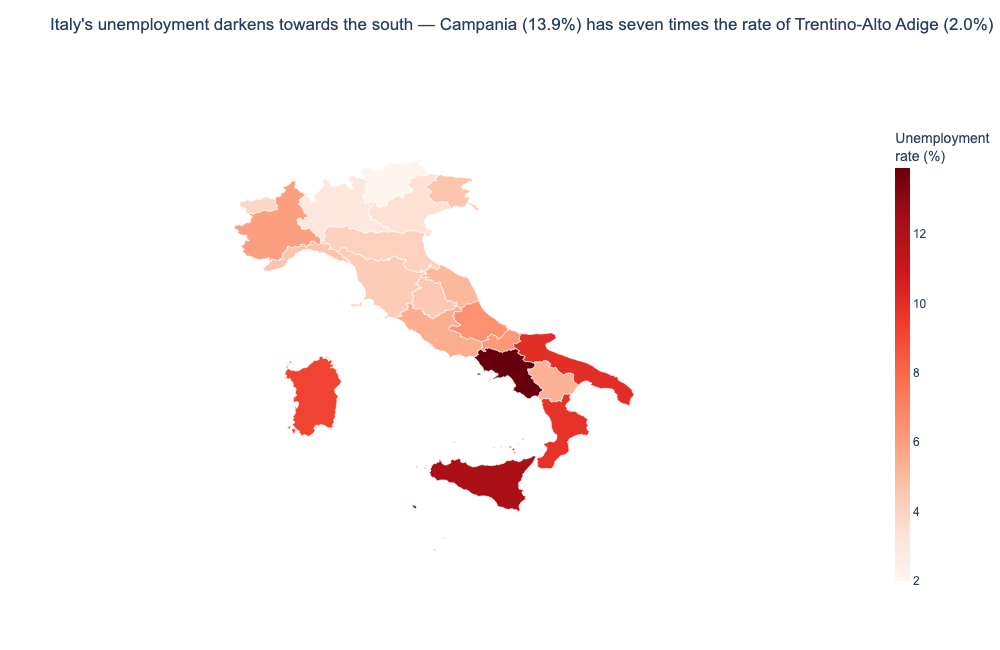

In [6]:
# Task 2

# ── Load the GeoJSON and inspect its properties ───────────────────────────────
with open('../data/italy_regions.geojson', 'r', encoding='utf-8') as file:
    italy_geojson = json.load(file)

print(italy_geojson['features'][0]['properties'])     # → the name lives in 'reg_name'

# ── Data: unemployment rate by region, 2025 annual average, age 15+ (Istat) ────
unemp = pd.DataFrame({
    'Region': [
        'Trentino-Alto Adige/Südtirol', 'Lombardia', 'Veneto', "Valle d'Aosta/Vallée d'Aoste",
        'Emilia-Romagna', 'Toscana', 'Umbria', 'Friuli-Venezia Giulia', 'Liguria', 'Marche',
        'Basilicata', 'Lazio', 'Piemonte', 'Molise', 'Abruzzo',
        'Sardegna', 'Calabria', 'Puglia', 'Sicilia', 'Campania'
    ],
    'Unemployment_pct': [
        2.0, 2.9, 3.4, 3.9,
        4.1, 4.3, 4.5, 4.6, 4.6, 5.1,
        5.3, 5.5, 6.0, 6.2, 6.5,
        9.2, 9.8, 10.0, 12.2, 13.9
    ]
})

# Check that every dataframe name matches a GeoJSON feature (otherwise regions silently stay blank)
geo_names = {f['properties']['reg_name'] for f in italy_geojson['features']}
print('Unmatched regions:', set(unemp['Region']) ^ geo_names)

top, low = unemp.loc[unemp['Unemployment_pct'].idxmax()], unemp.loc[unemp['Unemployment_pct'].idxmin()]

# ── Step 1: px.choropleth with custom GeoJSON ─────────────────────────────────
fig = px.choropleth(
    data_frame=unemp,
    geojson=italy_geojson,
    locations='Region',                     # column in dataframe
    featureidkey='properties.reg_name',     # matching key in GeoJSON properties
    color='Unemployment_pct',
    color_continuous_scale='Reds',          # sequential: one-directional rate
    fitbounds='locations',                  # auto-zoom to Italy
    hover_name='Region',
    hover_data={'Region': False, 'Unemployment_pct': ':.1f'},
    labels={'Unemployment_pct': 'Unemployment rate (%)'},
    title=(f"Italy's unemployment darkens towards the south — {top['Region']} ({top['Unemployment_pct']:.1f}%) "
           f"has seven times the rate of Trentino-Alto Adige ({low['Unemployment_pct']:.1f}%)"),
    height=650, width=1000,
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(visible=False),                # hide base world map and frame — only Italy's regions
    coloraxis_colorbar=dict(title='Unemployment<br>rate (%)', thickness=15, len=0.8),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.update_traces(marker_line_color='white', marker_line_width=0.8)
fig.show()